# About this notebook

English edition of the original support EDA, using a public working copy with names, emails, and ticket descriptions removed and resolution text reduced to a presence marker. This dataset has no churn label or customer link to the Telco data. The purchase-to-first-response interval is not a ticket response-time SLA. Satisfaction averages cover recorded scores on closed tickets.


In [1]:
from pathlib import Path
import sys
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents]
            if (p / "src" / "project_paths.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from project_paths import load_telco_source, load_support_source, output_dir
OUT = output_dir("data")

# Data is loaded from the included working copy in the next loading cell.


# ***Customer Support Ticket EDA***

## Load the data

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
tickets = load_support_source()
print("Public working copy shape:", tickets.shape)
display(tickets.head())
tickets.info()


Public working copy shape: (8469, 14)


,Ticket ID,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,Closed,Recorded,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,Closed,Recorded,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,Closed,Recorded,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Age                  8469 non-null   int64  
 2   Customer Gender               8469 non-null   object 
 3   Product Purchased             8469 non-null   object 
 4   Date of Purchase              8469 non-null   object 
 5   Ticket Type                   8469 non-null   object 
 6   Ticket Subject                8469 non-null   object 
 7   Ticket Status                 8469 non-null   object 
 8   Resolution                    2769 non-null   object 
 9   Ticket Priority               8469 non-null   object 
 10  Ticket Channel                8469 non-null   object 
 11  First Response Time           5650 non-null   object 
 12  Time to Resolution            2769 non-null   object 
 13  Cus

## Check data quality

In [4]:
print("\nMissing values:")
print(tickets.isnull().sum())

print("\nDuplicate rows:")
print(tickets.duplicated().sum())

print("\nDuplicate Ticket IDs:")
print(tickets["Ticket ID"].duplicated().sum())


Missing values:
Ticket ID                          0
Customer Age                       0
Customer Gender                    0
Product Purchased                  0
Date of Purchase                   0
Ticket Type                        0
Ticket Subject                     0
Ticket Status                      0
Resolution                      5700
Ticket Priority                    0
Ticket Channel                     0
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700
dtype: int64

Duplicate rows:
0

Duplicate Ticket IDs:
0


## Ticket type distribution

Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64


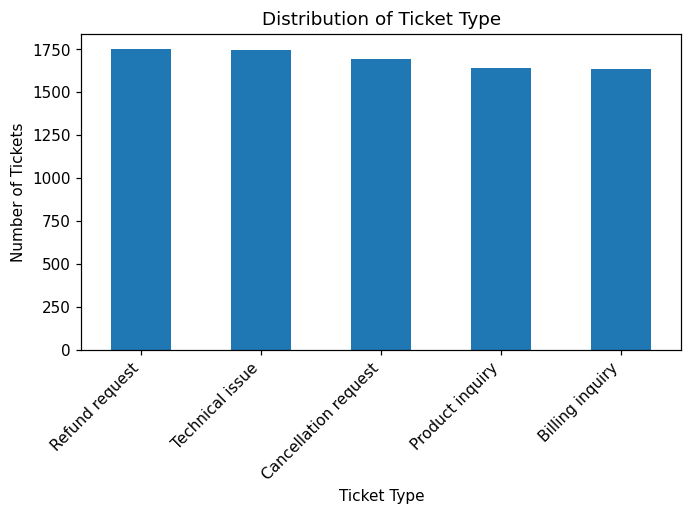

In [5]:

print(tickets["Ticket Type"].value_counts())

tickets["Ticket Type"].value_counts().plot(kind="bar")
plt.title("Distribution of Ticket Type")
plt.xlabel("Ticket Type")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Ticket status distribution

Ticket Status
Pending Customer Response    2881
Open                         2819
Closed                       2769
Name: count, dtype: int64


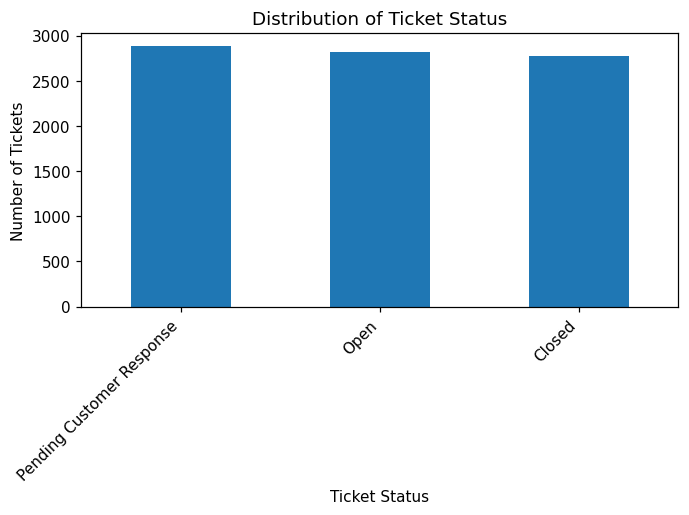

In [6]:

print(tickets["Ticket Status"].value_counts())

tickets["Ticket Status"].value_counts().plot(kind="bar")
plt.title("Distribution of Ticket Status")
plt.xlabel("Ticket Status")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Ticket priority distribution

Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64


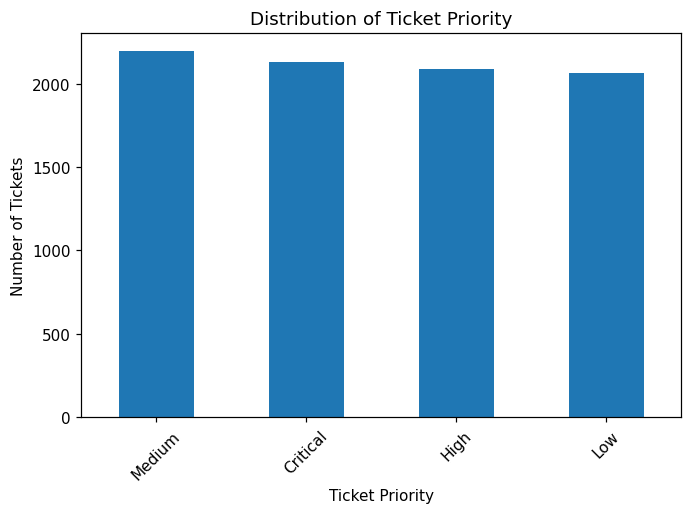

In [7]:

print(tickets["Ticket Priority"].value_counts())

tickets["Ticket Priority"].value_counts().plot(kind="bar")
plt.title("Distribution of Ticket Priority")
plt.xlabel("Ticket Priority")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Ticket Channel
Email           2143
Phone           2132
Social media    2121
Chat            2073
Name: count, dtype: int64


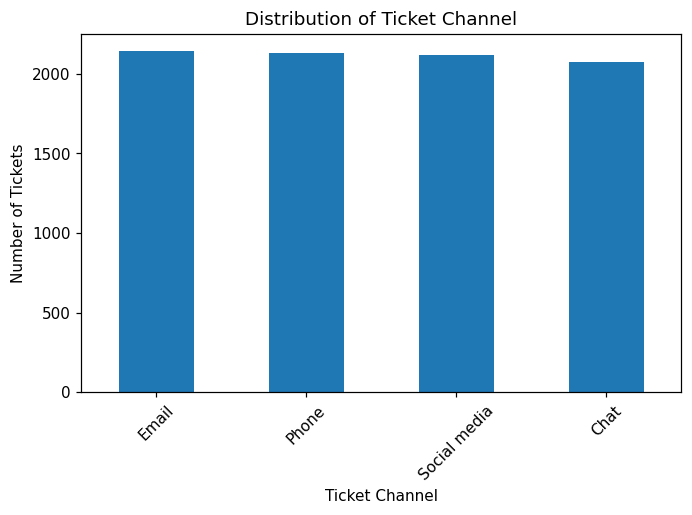

In [8]:

print(tickets["Ticket Channel"].value_counts())

tickets["Ticket Channel"].value_counts().plot(kind="bar")
plt.title("Distribution of Ticket Channel")
plt.xlabel("Ticket Channel")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Satisfaction score distribution

count    2769.000000
mean        2.991333
std         1.407016
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: Customer Satisfaction Rating, dtype: float64

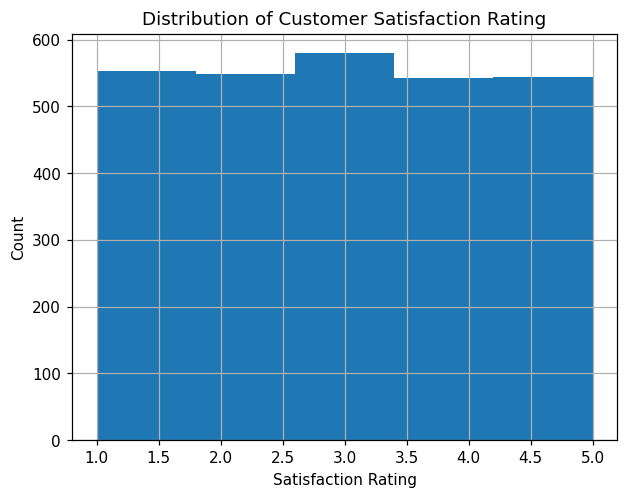

In [9]:
display(tickets["Customer Satisfaction Rating"].describe())

tickets["Customer Satisfaction Rating"].dropna().hist(bins=5)
plt.title("Distribution of Customer Satisfaction Rating")
plt.xlabel("Satisfaction Rating")
plt.ylabel("Count")
plt.show()

## Average satisfaction by ticket type

Ticket Type
Refund request          2.934564
Technical issue         2.958621
Product inquiry         3.016886
Billing inquiry         3.027574
Cancellation request    3.029070
Name: Customer Satisfaction Rating, dtype: float64

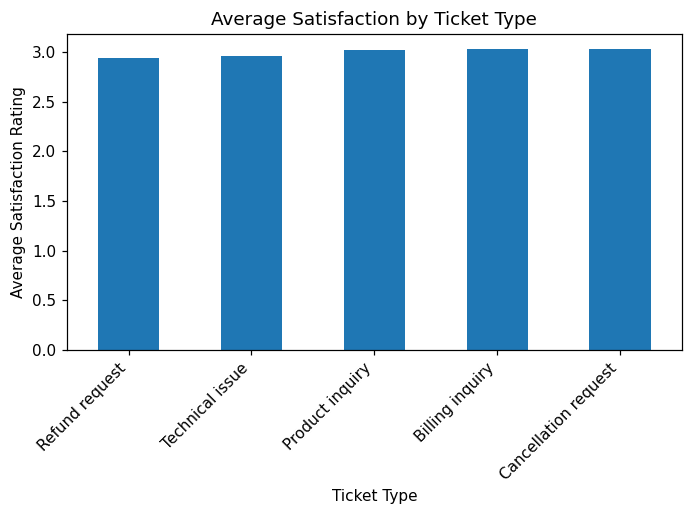

In [10]:
display(tickets.groupby("Ticket Type")["Customer Satisfaction Rating"].mean().sort_values())

tickets.groupby("Ticket Type")["Customer Satisfaction Rating"].mean().sort_values().plot(kind="bar")
plt.title("Average Satisfaction by Ticket Type")
plt.xlabel("Ticket Type")
plt.ylabel("Average Satisfaction Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Average satisfaction by priority

Ticket Priority
Critical    2.958678
Medium      2.976945
High        2.982979
Low         3.052795
Name: Customer Satisfaction Rating, dtype: float64

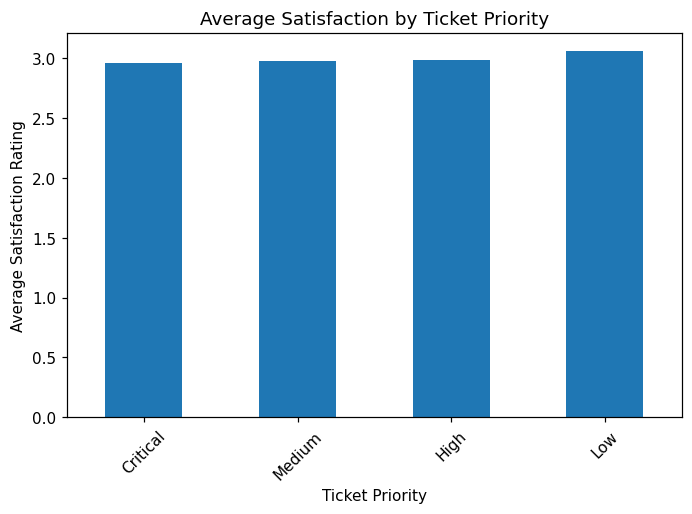

In [11]:
display(tickets.groupby("Ticket Priority")["Customer Satisfaction Rating"].mean().sort_values())

tickets.groupby("Ticket Priority")["Customer Satisfaction Rating"].mean().sort_values().plot(kind="bar")
plt.title("Average Satisfaction by Ticket Priority")
plt.xlabel("Ticket Priority")
plt.ylabel("Average Satisfaction Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Average satisfaction by channel

Ticket Channel
Phone           2.952243
Email           2.963889
Social media    2.969298
Chat            3.083086
Name: Customer Satisfaction Rating, dtype: float64

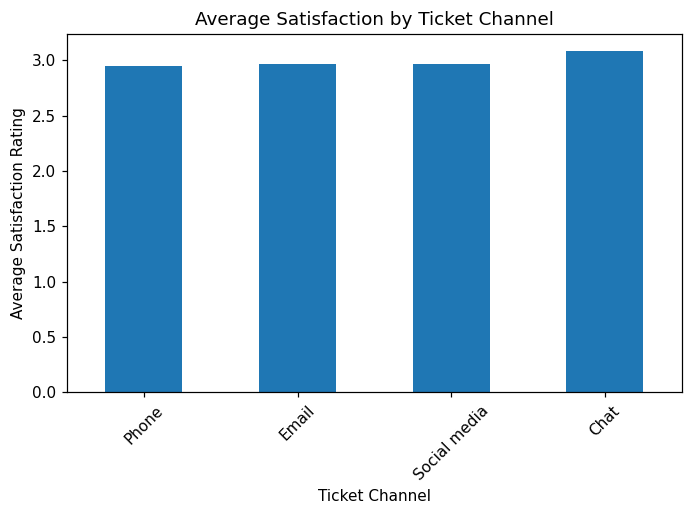

In [12]:
display(tickets.groupby("Ticket Channel")["Customer Satisfaction Rating"].mean().sort_values())

tickets.groupby("Ticket Channel")["Customer Satisfaction Rating"].mean().sort_values().plot(kind="bar")
plt.title("Average Satisfaction by Ticket Channel")
plt.xlabel("Ticket Channel")
plt.ylabel("Average Satisfaction Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Convert date columns

In [13]:
date_cols = ["Date of Purchase", "First Response Time", "Time to Resolution"]

for col in date_cols:
    tickets[col] = pd.to_datetime(tickets[col], errors="coerce")

print(tickets[date_cols].info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date of Purchase     8469 non-null   datetime64[ns]
 1   First Response Time  5650 non-null   datetime64[ns]
 2   Time to Resolution   2769 non-null   datetime64[ns]
dtypes: datetime64[ns](3)
memory usage: 198.6 KB
None


## Flag reversed timestamps




In [14]:
tickets["Response Time Hours"] = (
    tickets["First Response Time"] - tickets["Date of Purchase"]
).dt.total_seconds() / 3600

tickets["Resolution Time Hours"] = (
    tickets["Time to Resolution"] - tickets["First Response Time"]
).dt.total_seconds() / 3600

tickets["Invalid Time Record"] = (
    (tickets["First Response Time"].notnull()) &
    (tickets["Time to Resolution"].notnull()) &
    (tickets["Time to Resolution"] < tickets["First Response Time"])
).map({True: "Invalid", False: "Valid"})

invalid_time = tickets[tickets["Invalid Time Record"] == "Invalid"]

print("\nRecords with resolution earlier than first response:")
print(invalid_time.shape[0])

print("\nExample reversed-timestamp records:")
display(invalid_time[[
    "Ticket ID",
    "Ticket Status",
    "First Response Time",
    "Time to Resolution"
]].head())


Records with resolution earlier than first response:
1365

Example reversed-timestamp records:


,Ticket ID,Ticket Status,First Response Time,Time to Resolution
3,4,Closed,2023-06-01 07:29:40,2023-06-01 01:57:40
10,11,Closed,2023-06-01 17:46:49,2023-05-31 23:51:49
11,12,Closed,2023-06-01 12:05:51,2023-06-01 09:27:51
14,15,Closed,2023-06-01 06:22:55,2023-05-31 23:08:55
16,17,Closed,2023-06-01 19:46:59,2023-06-01 15:58:59


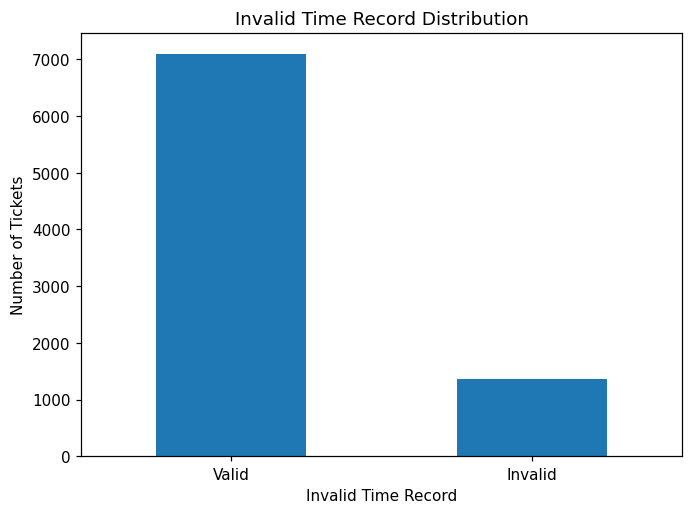

In [15]:
tickets["Invalid Time Record"].value_counts().plot(kind="bar")
plt.title("Invalid Time Record Distribution")
plt.xlabel("Invalid Time Record")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Distribution of available valid resolution intervals

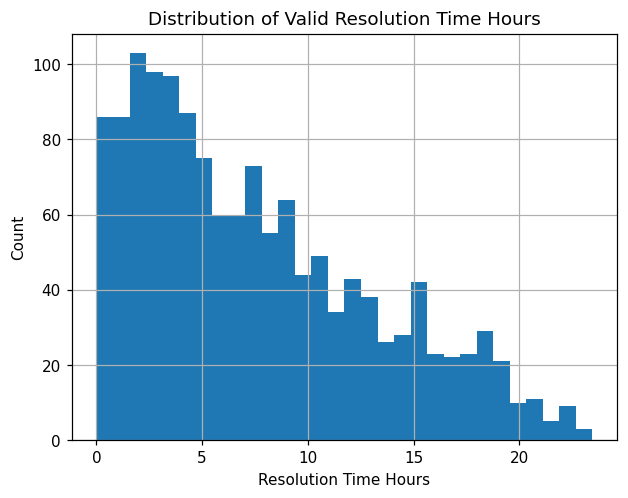

In [16]:
valid_resolution = tickets[
    (tickets["Invalid Time Record"] == "Valid") &
    (tickets["Resolution Time Hours"].notnull())
]

valid_resolution["Resolution Time Hours"].hist(bins=30)
plt.title("Distribution of Valid Resolution Time Hours")
plt.xlabel("Resolution Time Hours")
plt.ylabel("Count")
plt.show()

## Closed-ticket indicator

In [17]:
tickets["Is Closed"] = (tickets["Ticket Status"] == "Closed").map({
    True: 1,
    False: 0
})

print(tickets["Is Closed"].value_counts())

Is Closed
0    5700
1    2769
Name: count, dtype: int64


## Export data for Power BI

In [18]:
tickets.to_csv(OUT / "support_tickets_powerbi.csv", index=False)

print("support_tickets_powerbi.csv exported.")

support_tickets_powerbi.csv exported.
